In [1]:
from sklearn.model_selection import train_test_split

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("IMDB Dataset.csv")

In [4]:
df.shape

(50000, 2)

In [5]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [7]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [8]:
df['sentiment'].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [10]:
df['review'].duplicated().sum()

np.int64(418)

In [11]:
df.duplicated().sum()

np.int64(418)

In [12]:
df= df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(49582, 2)

In [15]:
df['review'].str.contains('<br />', regex=False).sum()

np.int64(28966)

In [16]:
df['review']= df['review'].str.replace('<br />',' ', regex=False)

In [17]:
df['review'].str.contains('<br />', regex=False).sum()

np.int64(0)

In [18]:
df['review']= df['review'].str.lower()

In [19]:
df['review'].head()

0    one of the other reviewers has mentioned that ...
1    a wonderful little production.   the filming t...
2    i thought this was a wonderful way to spend ti...
3    basically there's a family where a little boy ...
4    petter mattei's "love in the time of money" is...
Name: review, dtype: str

In [20]:
import string

print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [21]:
def remove_punch(text):
    return text.translate(str.maketrans('','', string.punctuation))

In [22]:
df['review']= df['review'].apply(remove_punch)

In [23]:
df['review'].head()

0    one of the other reviewers has mentioned that ...
1    a wonderful little production   the filming te...
2    i thought this was a wonderful way to spend ti...
3    basically theres a family where a little boy j...
4    petter matteis love in the time of money is a ...
Name: review, dtype: str

In [24]:
df['review']= df['review'].str.replace(r'\s+',' ', regex=True)

In [25]:
df['review']= df['review'].str.strip()

In [26]:
X=df['review']
y=df['sentiment']

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(39665,)
(9917,)
(39665,)
(9917,)


In [29]:
print(X_train.shape)
print(X_test.shape)

print(y_train.value_counts())
print(y_test.value_counts())

(39665,)
(9917,)
sentiment
positive    19907
negative    19758
Name: count, dtype: int64
sentiment
positive    4977
negative    4940
Name: count, dtype: int64


In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [31]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(39665, 146919)
(9917, 146919)


In [32]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

In [33]:
print(y_pred[:20])

['negative' 'positive' 'positive' 'negative' 'negative' 'positive'
 'negative' 'negative' 'positive' 'negative' 'negative' 'positive'
 'positive' 'negative' 'positive' 'negative' 'positive' 'negative'
 'positive' 'negative']


In [34]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8658868609458505


In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.85      0.89      0.87      4940
    positive       0.88      0.84      0.86      4977

    accuracy                           0.87      9917
   macro avg       0.87      0.87      0.87      9917
weighted avg       0.87      0.87      0.87      9917



In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[4382  558]
 [ 772 4205]]


In [37]:
newreview= ['This good movie']
newreviewtfidf= tfidf.transform(newreview)
prediction = model.predict(newreviewtfidf)
print(prediction)

['negative']


In [38]:
print(model.classes_)

['negative' 'positive']


In [39]:
print(model.predict_proba(newreviewtfidf))

[[0.54316249 0.45683751]]


In [40]:
reviews = [
    "This movie was absolutely fantastic and amazing",
    "This movie was terrible and boring",
    "I loved this movie and would highly recommend it",
    "I hated this movie and it was a complete waste of time"
]

reviews_tfidf = tfidf.transform(reviews)

predictions = model.predict(reviews_tfidf)
probabilities = model.predict_proba(reviews_tfidf)

print(predictions)
print(probabilities)

['positive' 'negative' 'positive' 'negative']
[[0.19400234 0.80599766]
 [0.92465334 0.07534666]
 [0.19870804 0.80129196]
 [0.904481   0.095519  ]]


In [41]:
r= ["this is a good movie i will watch it again."]
r_tfidf= tfidf.transform(r)
pred= model.predict(r_tfidf)
print(pred)
probabilities = model.predict_proba(r_tfidf)
print(probabilities)

['positive']
[[0.46886095 0.53113905]]


In [42]:
TfidfVectorizer(ngram_range=(1, 2))

,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\

In [43]:
tfidf_bigram = TfidfVectorizer(ngram_range=(1, 2))

In [44]:
X_train_bigram= tfidf_bigram.fit_transform(X_train)

X_test_bigram= tfidf_bigram.transform(X_test)

In [45]:
model_bigram = MultinomialNB()

model_bigram.fit(X_train_bigram, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[19758.,19907.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.7 ,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](2,)","['negative','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2273541)","[[0.12,0. ,0. ,...,0.08,0.08,0.08], [0.37,0.18,0.06,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 2273541)","[[-14.65,-14.77,-14.77,...,-14.69,-14.69,-14.69], [-14.45,-14.6 ,-14.71,...,-14.77,-14.77,-14.77]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2273541


In [46]:
y_pred_bigram= model_bigram.predict(X_test_bigram)

In [47]:
accuracy_bigram= accuracy_score(y_test, y_pred_bigram)

print(accuracy_bigram)

0.8906927498235353


In [48]:
print(classification_report(y_test, y_pred_bigram))

              precision    recall  f1-score   support

    negative       0.88      0.90      0.89      4940
    positive       0.90      0.88      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



In [49]:
r1= ["this is a good movie."]
r1_tfidf= tfidf_bigram.transform(r1)
pred1= model_bigram.predict(r1_tfidf)
print(pred1)
probabilities1 = model_bigram.predict_proba(r1_tfidf)
print(probabilities1)

['positive']
[[0.4337009 0.5662991]]


In [50]:
reviews = [
    "I absolutely loved this movie",
    "This movie was terrible",
    "This movie was not good",
    "This movie was not bad",
    "The acting was amazing but the story was boring",
    "I would never recommend this movie"
]

reviews_tfidf = tfidf_bigram.transform(reviews)

predictions = model_bigram.predict(reviews_tfidf)

for review, prediction in zip(reviews, predictions):
    print(review, "→", prediction)

I absolutely loved this movie → positive
This movie was terrible → negative
This movie was not good → negative
This movie was not bad → negative
The acting was amazing but the story was boring → negative
I would never recommend this movie → negative


In [51]:
from sklearn.linear_model import LogisticRegression

In [52]:
lr_model = LogisticRegression(max_iter=1000)

In [53]:
lr_model.fit(X_train_bigram, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [54]:
y_pred_lr = lr_model.predict(X_test_bigram)

In [55]:
accuracy_lr = accuracy_score(y_test,y_pred_lr)
print("logictic regression accuracy:", accuracy_lr)
print("percentage:", round(accuracy_lr*100,2),"%")

logictic regression accuracy: 0.8987597055561157
percentage: 89.88 %


In [56]:
print (classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

    negative       0.91      0.88      0.90      4940
    positive       0.89      0.91      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [57]:
results = {
    "Model": [
        "Naive Bayes (Unigrams)",
        "Naive Bayes (Bigrams)",
        "Logistic Regression (Bigrams)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_bigram,
        accuracy_lr
    ]
}

results_df = pd.DataFrame(results)

results_df["Accuracy (%)"] = (
    results_df["Accuracy"] * 100
).round(2)

print(results_df)

                           Model  Accuracy  Accuracy (%)
0         Naive Bayes (Unigrams)  0.865887         86.59
1          Naive Bayes (Bigrams)  0.890693         89.07
2  Logistic Regression (Bigrams)  0.898760         89.88


[[4361  579]
 [ 425 4552]]


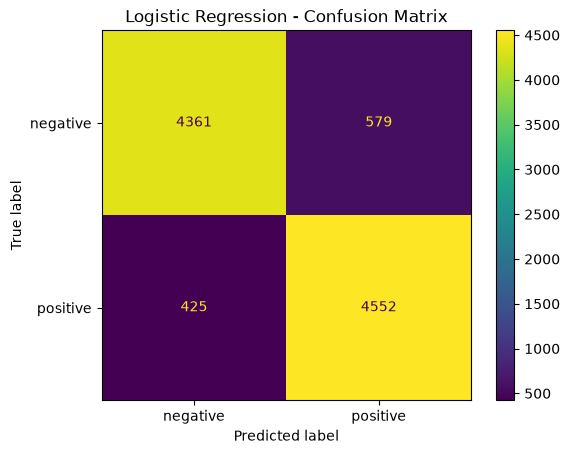

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=lr_model.classes_
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [59]:
TN, FP, FN, TP = cm.ravel()

accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

f1_score = 2 * precision * recall / (precision + recall)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1_score, 4))

Accuracy: 89.88 %
Precision: 0.8872
Recall: 0.9146
F1-score: 0.9007


In [60]:
new_reviews = [
    "This movie was absolutely fantastic and enjoyable",
    "This movie was terrible and boring",
    "The acting was good but the story was disappointing"
]

new_reviews_tfidf = tfidf_bigram.transform(new_reviews)

predictions = lr_model.predict(new_reviews_tfidf)

for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print("-" * 50)

Review: This movie was absolutely fantastic and enjoyable
Predicted sentiment: positive
--------------------------------------------------
Review: This movie was terrible and boring
Predicted sentiment: negative
--------------------------------------------------
Review: The acting was good but the story was disappointing
Predicted sentiment: negative
--------------------------------------------------


In [61]:
import joblib

joblib.dump(lr_model, "sentiment_model.pkl")
joblib.dump(tfidf_bigram, "tfidf_vectorizer.pkl")

print("Models saved successfully!")

Models saved successfully!
